## Unequal Housing Conditions in Boston: Census Tract Geodemographic Data Analysis
### Spatial Clustering and Regionalization

We leverage clustering to help better understand the similarities within and the differences between each cluster based on certain census tract information. For instance, we may find that certain clusters have higher rates across some variables while consistently lower rates across others. Understanding these similarities and differences will help gain meaningful insights from complex data. These insights can be distilled down into cluster profiles, which can be used to easily describe each group.

* From our unequal housing work which seeks to gain insights on the effects of molds, rodents/pests, or lack of heating/ventilation on Asthma disparities in Boston, we use census data to explore demographic dynamics such as total population, total population in occupied housing units, total number of renter occupied in housing units, population in labor force and unemployed, population with income below poverty level in past 12 months, population with less than a high school diploma, etc.

#### Collecting geodemographic data for modeling
* **Extracting Boston census tract data using the Census API**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import geopandas as gpd
from census import Census 
from us import states


In [2]:
# Set API key
c = Census("66a371cf269bb383d7d8d7b65256b791025e88fd")


The data that we are pulling will come from the Annual [Community Survey (ACS)](https://api.census.gov/data/2020/acs/acs5/variables.html) which give census data at the travel level for MA.


In [3]:
# Grabbing a few variables of interest pertaining to the economic vitality of an area
geo_demo = [
    "B01003_001E", #"Total Population"
    "B25077_001E", #"Median value of owner occupied units"
    "B25026_001E", #"Total population in occupied housing units"
    "B25008_002E", #"Total number of owner occupied units"
    "B25008_003E", #"Total number of renter occupied units"
    "B06009_002E", #"Population with less than a high school diploma"
    "B06009_003E", #"Population with high school diploma or equivalent"
    "B06009_004E", #"Population with some college/associates degree"
    "B06009_005E", #"Population with bachelors degree"
    "B06009_006E", #"Population with a graduate degree"
    "B01002_001E", #"Median age"
    "B06010_004E", #"Population with income less than 9999"
    "B06010_005E", #"Population with income between 10000 and 14999"
    "B06010_006E", #"Population with income between 15000 and 24999"
    "B06010_007E", #"Population with income between 25000 and 34999"
    "B06010_008E", #"Population with income between 35000 and 49999"
    "B06010_009E", #"Population with income between 50000 and 64999"
    "B06010_010E", #"Population with income between 65000 and 74999"
    "B06010_011E", #"Population with income of 75000 or more"
    "B28007_009E", #"Population in labor force and unemployed"
    "B19059_002E", #"Population that is retired with retirement income"
    "B19059_003E", #"Retired without retirement income"
    "B08013_001E", #"Travel time to work in minutes"
    "B17013_002E" #"Population with income below poverty level in past 12 months"
        ]


In [4]:
# How these parameters are passed to the API. 
# https://www2.census.gov/geo/docs/reference/codes2020/cou/st25_ma_cou2020.txt (for state,county fp)
boston_census = c.acs5.state_county_tract(fields = ('NAME', 'B01003_001E','B25026_001E','B25008_002E','B25008_003E',
                                               'B25077_001E','B06009_002E','B06009_003E','B06009_004E',
                                               'B06009_005E','B06009_006E',
                                               'B01002_001E','B06010_004E','B06010_005E','B06010_006E',
                                               'B06010_007E','B06010_008E','B06010_009E','B06010_010E',
                                               'B06010_011E','B28007_009E','B19059_002E','B19059_003E',
                                               'B08013_001E','B17013_002E'),
                                      state_fips = states.MA.fips,
                                      county_fips = "025",
                                      tract = "*",
                                      year = 2020)


In [5]:
# Create a dataframe from the census data
import pandas as pd
boston_df = pd.DataFrame(boston_census)

# Show the dataframe and its print its shape
print(boston_df.head(2))
print('Shape of Boston DataFrame:', boston_df.shape)


                                               NAME  B01003_001E  B25026_001E  \
0  Census Tract 1.01, Suffolk County, Massachusetts       2031.0       2025.0   
1  Census Tract 1.02, Suffolk County, Massachusetts       3786.0       3752.0   

   B25008_002E  B25008_003E  B25077_001E  B06009_002E  B06009_003E  \
0        591.0       1434.0     483800.0         30.0        185.0   
1        759.0       2993.0     599100.0        340.0        595.0   

   B06009_004E  B06009_005E  ...  B06010_010E  B06010_011E  B28007_009E  \
0        117.0        457.0  ...        122.0        335.0         84.0   
1        477.0       1373.0  ...        342.0        340.0         48.0   

   B19059_002E  B19059_003E  B08013_001E  B17013_002E  state  county   tract  
0         70.0        557.0      36615.0          0.0     25     025  000101  
1        153.0       1169.0      68965.0         93.0     25     025  000102  

[2 rows x 28 columns]
Shape of Boston DataFrame: (235, 28)


In [7]:
# Access shapefile of MA census tracts
ma_tract = gpd.read_file("https://www2.census.gov/geo/tiger/TIGER2020/TRACT/tl_2020_25_tract.zip")

# Reprojecting the shapefile to the Massachusetts Island 
# EPSG:2250 - https://spatialreference.org/ref/epsg/2250/
ma_tract = ma_tract.to_crs(epsg = 2250)

# Print GeoDataFrame of the MA census tract shapefile
print(ma_tract.head(2))
print('MA Tract Shape: ', ma_tract.shape)

# Check projection of the shapefile
print("\nThe shapefile projection for this data is: {}".format(ma_tract.crs))


  STATEFP COUNTYFP TRACTCE        GEOID     NAME              NAMELSAD  MTFCC  \
0      25      009  265102  25009265102  2651.02  Census Tract 2651.02  G5020   
1      25      009  268200  25009268200     2682     Census Tract 2682  G5020   

  FUNCSTAT     ALAND  AWATER     INTPTLAT      INTPTLON  \
0        S  16318373  134252  +42.7338220  -070.9600766   
1        S  10737361  364499  +42.8117773  -070.9054643   

                                            geometry  
0  POLYGON ((1508486.574 632294.589, 1508493.015 ...  
1  POLYGON ((1527503.293 652987.231, 1527509.545 ...  
MA Tract Shape:  (1620, 13)

The shapefile projection for this data is: EPSG:2250


In [8]:
# Combine the state, county, and tract variables of the boston_df together to create a new string and assign to variable called GEOID
boston_df["GEOID"] = boston_df["state"] + boston_df["county"] + boston_df["tract"]


In [9]:
# Remove the individual columns as they're no longer needed
boston_df = boston_df.drop(columns = ["state", "county", "tract"])


In [10]:
# Merge the Census data stored in boston_df with the geographic data stored in the ma_tract data
# Join the data together on GEOID to geoenable the census data
ma_merge = ma_tract.merge(boston_df, on = "GEOID")


In [11]:
# Display the results
ma_merge.head(2)


,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME_x,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,...,B06010_007E,B06010_008E,B06010_009E,B06010_010E,B06010_011E,B28007_009E,B19059_002E,B19059_003E,B08013_001E,B17013_002E
0,25,025,140202,25025140202,1402.02,Census Tract 1402.02,G5020,S,1538599,17120,...,720.0,764.0,446.0,233.0,1104.0,261.0,515.0,1646.0,125630.0,115.0
1,25,025,140300,25025140300,1403,Census Tract 1403,G5020,S,1548879,38736,...,472.0,867.0,1009.0,354.0,495.0,897.0,363.0,2407.0,97375.0,347.0


### Cleaning the extracted data


In [12]:
# Renaming variables in the data set
ma_merge.rename(columns={
    "B01003_001E":"TotPop", #"Total Population"
    "B25077_001E":"MedVal_OwnOccUnit", #"Median value of owner occupied units"
    "B25026_001E":"TotPopOccUnits", #"Total population in occupied housing units"
    "B25008_002E":"TotNumOwnOccUnit", #"Total number of owner occupied units"
    "B25008_003E":"TotNumRentOccUnit", #"Total number of renter occupied units"
    "B06009_002E":"PopLTHSDip", #"Population with less than a high school diploma"
    "B06009_003E":"PopHSDip", #"Population with high school diploma or equivalent"
    "B06009_004E":"PopAssoc", #"Population with some college/associates degree"
    "B06009_005E":"PopBA", #"Population with bachelors degree"
    "B06009_006E":"PopGrad", #"Population with a graduate degree"
    "B01002_001E":"MedAge", #"Median age"
    "B06010_004E":"PopIncLT10", #"Population with income less than 9999"
    "B06010_005E":"PopInc1015", #"Population with income between 10000 and 14999"
    "B06010_006E":"PopInc1525", #"Population with income between 15000 and 24999"
    "B06010_007E":"PopInc2535", #"Population with income between 25000 and 34999"
    "B06010_008E":"PopInc3550", #"Population with income between 35000 and 49999"
    "B06010_009E":"PopInc5065", #"Population with income between 50000 and 64999"
    "B06010_010E":"PopInc6575", #"Population with income between 65000 and 74999"
    "B06010_011E":"PopIncGT75", #"Population with income of 75000 or more"
    "B28007_009E":"UnempPop", #"Population in labor force and unemployed"
    "B19059_002E":"RetPop", #"Population that is retired with retirement income"
    "B19059_003E":"RetPopNoRetInc", #"Retired without retirement income"
    "B08013_001E":"TrvTimWrk", #"Travel time to work in minutes"
    "B17013_002E":"PopBlwPovLvl" #"Population with income below poverty level in past 12 months"
}
                , inplace=True
               )


In [13]:
# Creating a list of variables that will be used to subset the DataFrame to only the variables that will be used for clustering.
geo_rn = [
"TotPop", #"Total Population"
"TotPopOccUnits", #"Total population in occupied housing units"
"TotNumOwnOccUnit", #"Total number of owner occupied units"
"TotNumRentOccUnit", #"Total number of renter occupied units"
"PopLTHSDip", #"Population with less than a high school diploma"
"PopHSDip", #"Population with high school diploma or equivalent"
"PopAssoc", #"Population with some college/associates degree"
"PopBA", #"Population with bachelors degree"
"PopGrad", #"Population with a graduate degree"
"PopIncLT10", #"Population with income less than 9999"
"PopInc1015", #"Population with income between 10000 and 14999"
"PopInc1525", #"Population with income between 15000 and 24999"
"PopInc2535", #"Population with income between 25000 and 34999"
"PopInc3550", #"Population with income between 35000 and 49999"
"PopInc5065", #"Population with income between 50000 and 64999"
"PopInc6575", #"Population with income between 65000 and 74999"
"PopIncGT75", #"Population with income of 75000 or more"
"UnempPop", #"Population in labor force and unemployed"
"RetPop", #"Population that is retired with retirement income"
"RetPopNoRetInc", #"Retired without retirement income"
"PopBlwPovLvl" #"Population with income below poverty level in past 12 months"
]

# Cleaning up the dataframe
geo_rn.append('geometry')
# you’ll create a list of variables that will be used to subset the DataFrame to only the variables that will be used in the clustering exercise later on.
ma_merge_2 = ma_merge[geo_rn]
geo_rn.remove('geometry')


In [14]:
# Remove any census tracts where there is no population, will not be useful for clustering.
ma_merge_2 = ma_merge_2[ma_merge_2['TotPop']>0]

# Resetting the index to assist in index based operations later on
ma_merge_2.reset_index(inplace=True)


### Conducting EDA and ESDA


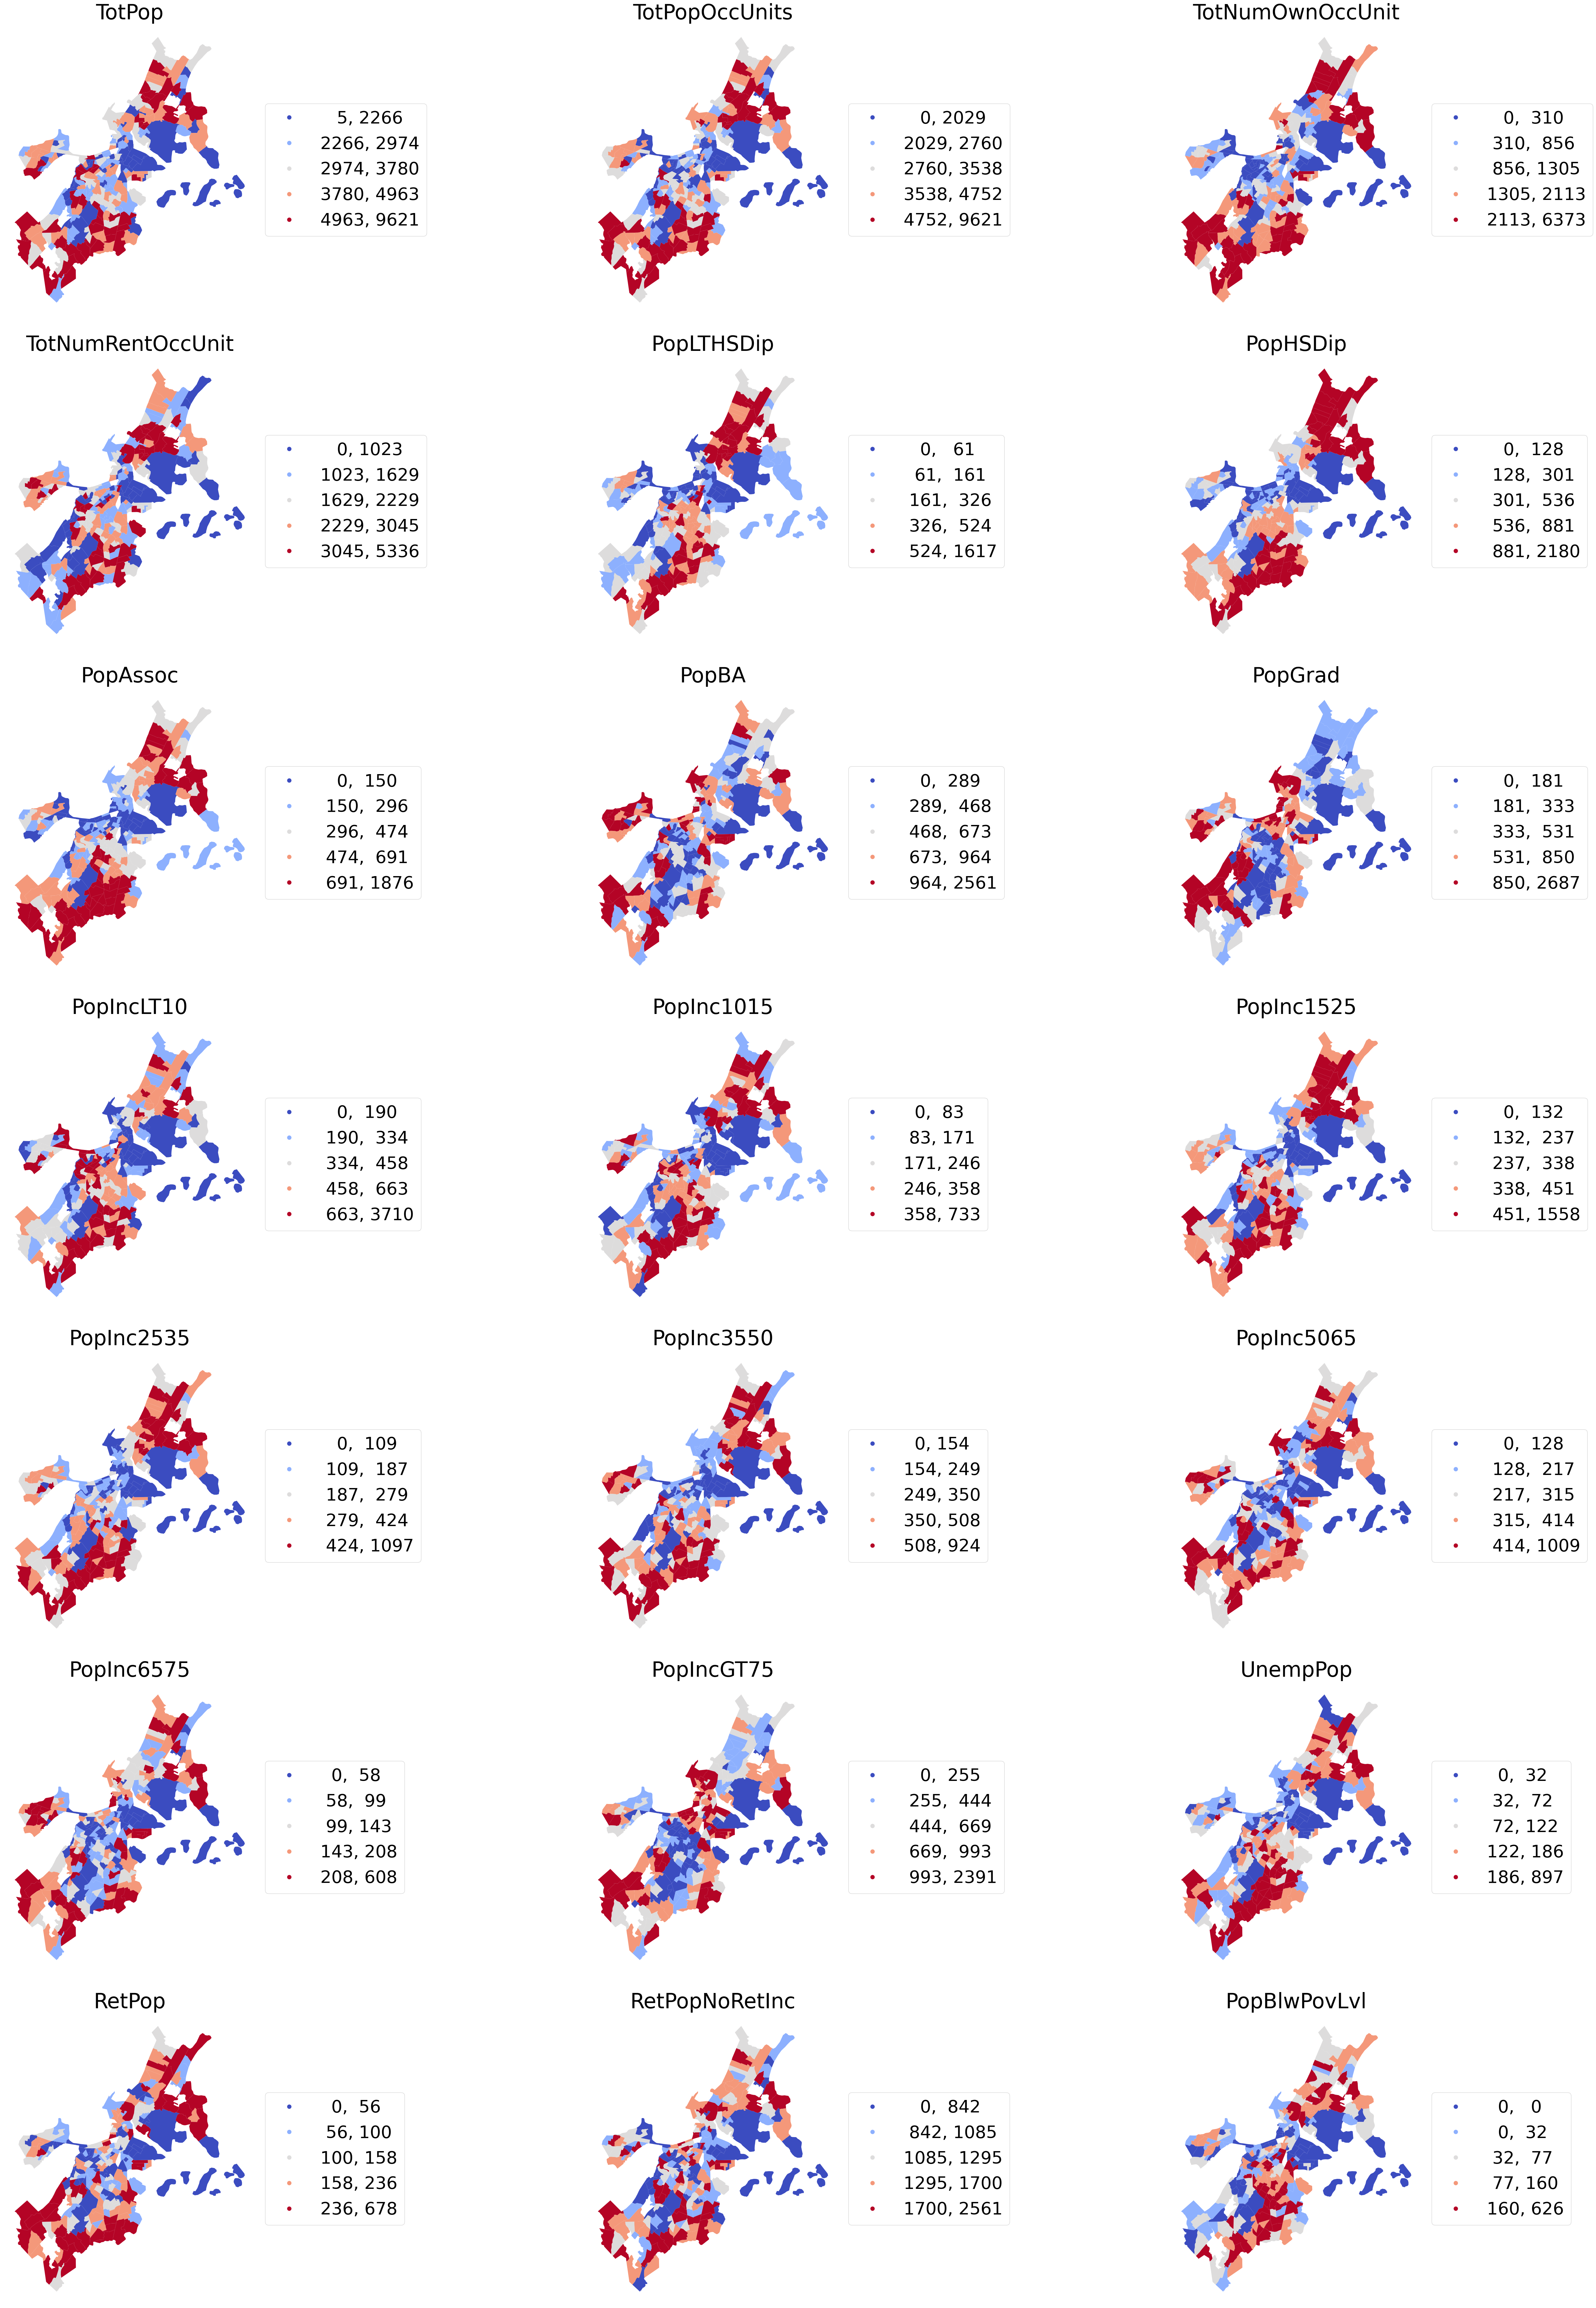

In [15]:
# Setting up the figure using subplots to map each of the extracted variables
import matplotlib.pyplot as plt
fig, axes = plt.subplots(nrows=7, ncols=3, figsize=(75,75), layout='tight')

axes = axes.flatten()

# Setting the font size
plt.rcParams['font.size'] = '40'

# Plotting each of the extracted variables in a subplot
for ind, col in enumerate(geo_rn):
    ax = axes[ind]
    ma_merge_2.plot(column=col,
                  ax = ax, scheme = "quantiles", linewidth=0, cmap="coolwarm", 
                    legend=True, legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"}
                 ) 
    ax.set_axis_off()
    ax.set_title(col)
plt.subplots_adjust(wspace=None, hspace=None)
plt.show()


**From the subplots above, we can see areas with higher values displayed in red, and areas with lower values displayed in blue.**
* Visually, there are a number of patterns that begin to emerge.

1. The total number of renter-occupied  units **("TotNumRentOccUnit")** is also very low only around the West Roxbury area and they also have the population with the lowest less than high school diploma. But it is very high around Roslindale, Hyde Park Mattapan, Dorchester and the Downtown areas.
2. The total number of owner-occupied  units **("TotNumOwnOccUnit")** is also very high around West Roxbury, Charlestown, and some part of East Boston.
3. The total population below poverty level **("PopBlwPovLvl")** is also very high around Hyde Park, Mattapan, and some part of Dorchester.
4. The population in labor force but unemployed **("UnempPop")** is also very high around West Roxbury, Hyde Park, Mattapan, and some part of East Boston.
5. We can see a higher proportion of the population with an associate’s degree or less education comparing **"PopAssoc"** to "PopBA" and "PopGrad".
6. When you look closer at Aliston/Brighton, West Roxbury and Downtown areas, there are larger numbers of the population with bachelors and graduate-level degrees. 
 

* The differences and commonalities across space will benefit the performance of your clustering models and the differentiation of the resulting cluster profiles. 
* **NB:** If all of the spatial visuals showed relatively similar patterns, then there would not be a huge benefit gained from leveraging spatial clustering methodologies.


### Measuring spatial autocorrelation


In [19]:
# Importing packages required for testing spatial autocorrelation
from libpysal.weights import Queen, KNN
from esda.moran import Moran

# Testing for spatial auto correlation using Moran's I. First, we need to set up the spatial weights matrix
w = Queen.from_dataframe(ma_merge_2)


C:\Users\174006\boston-env\lib\site-packages\libpysal\cg\alpha_shapes.py:39: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def nb_dist(x, y):
C:\Users\174006\boston-env\lib\site-packages\libpysal\cg\alpha_shapes.py:165: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def get_faces(triangle):
C:\Users\174006\boston-env\lib\site-packages\libpysal\cg\alpha_shapes.py:

In [20]:
# Set the numpy random seed for reproducibility
np.random.seed(54321)

# Calculate the Moran's I statistic for each geodemographic variable
moransi_results = [
    Moran(ma_merge_2[v], w) for v in geo_rn
]

# Structure results as a list of tuples
moransi_results = [
    (v, res.I, res.p_sim)
    for v, res in zip(geo_rn, moransi_results)
]

# Display as a table
table = pd.DataFrame(
    moransi_results, columns=["GEODEMO Var", "Moran's I", "P-value"]
).set_index("GEODEMO Var")

table.head(5)


,Moran's I,P-value
GEODEMO Var,,
TotPop,0.260643,0.001
TotPopOccUnits,0.325849,0.001
TotNumOwnOccUnit,0.520722,0.001
TotNumRentOccUnit,0.188860,0.001
PopLTHSDip,0.471506,0.001


For the selected variable, as well as those not displayed, there is a statistically significant non-random spatial pattern inherent in the data.
* This shows that the data is spatially random


* We can explore the data is by producing pairplots by using to displays the correlation between variables. 


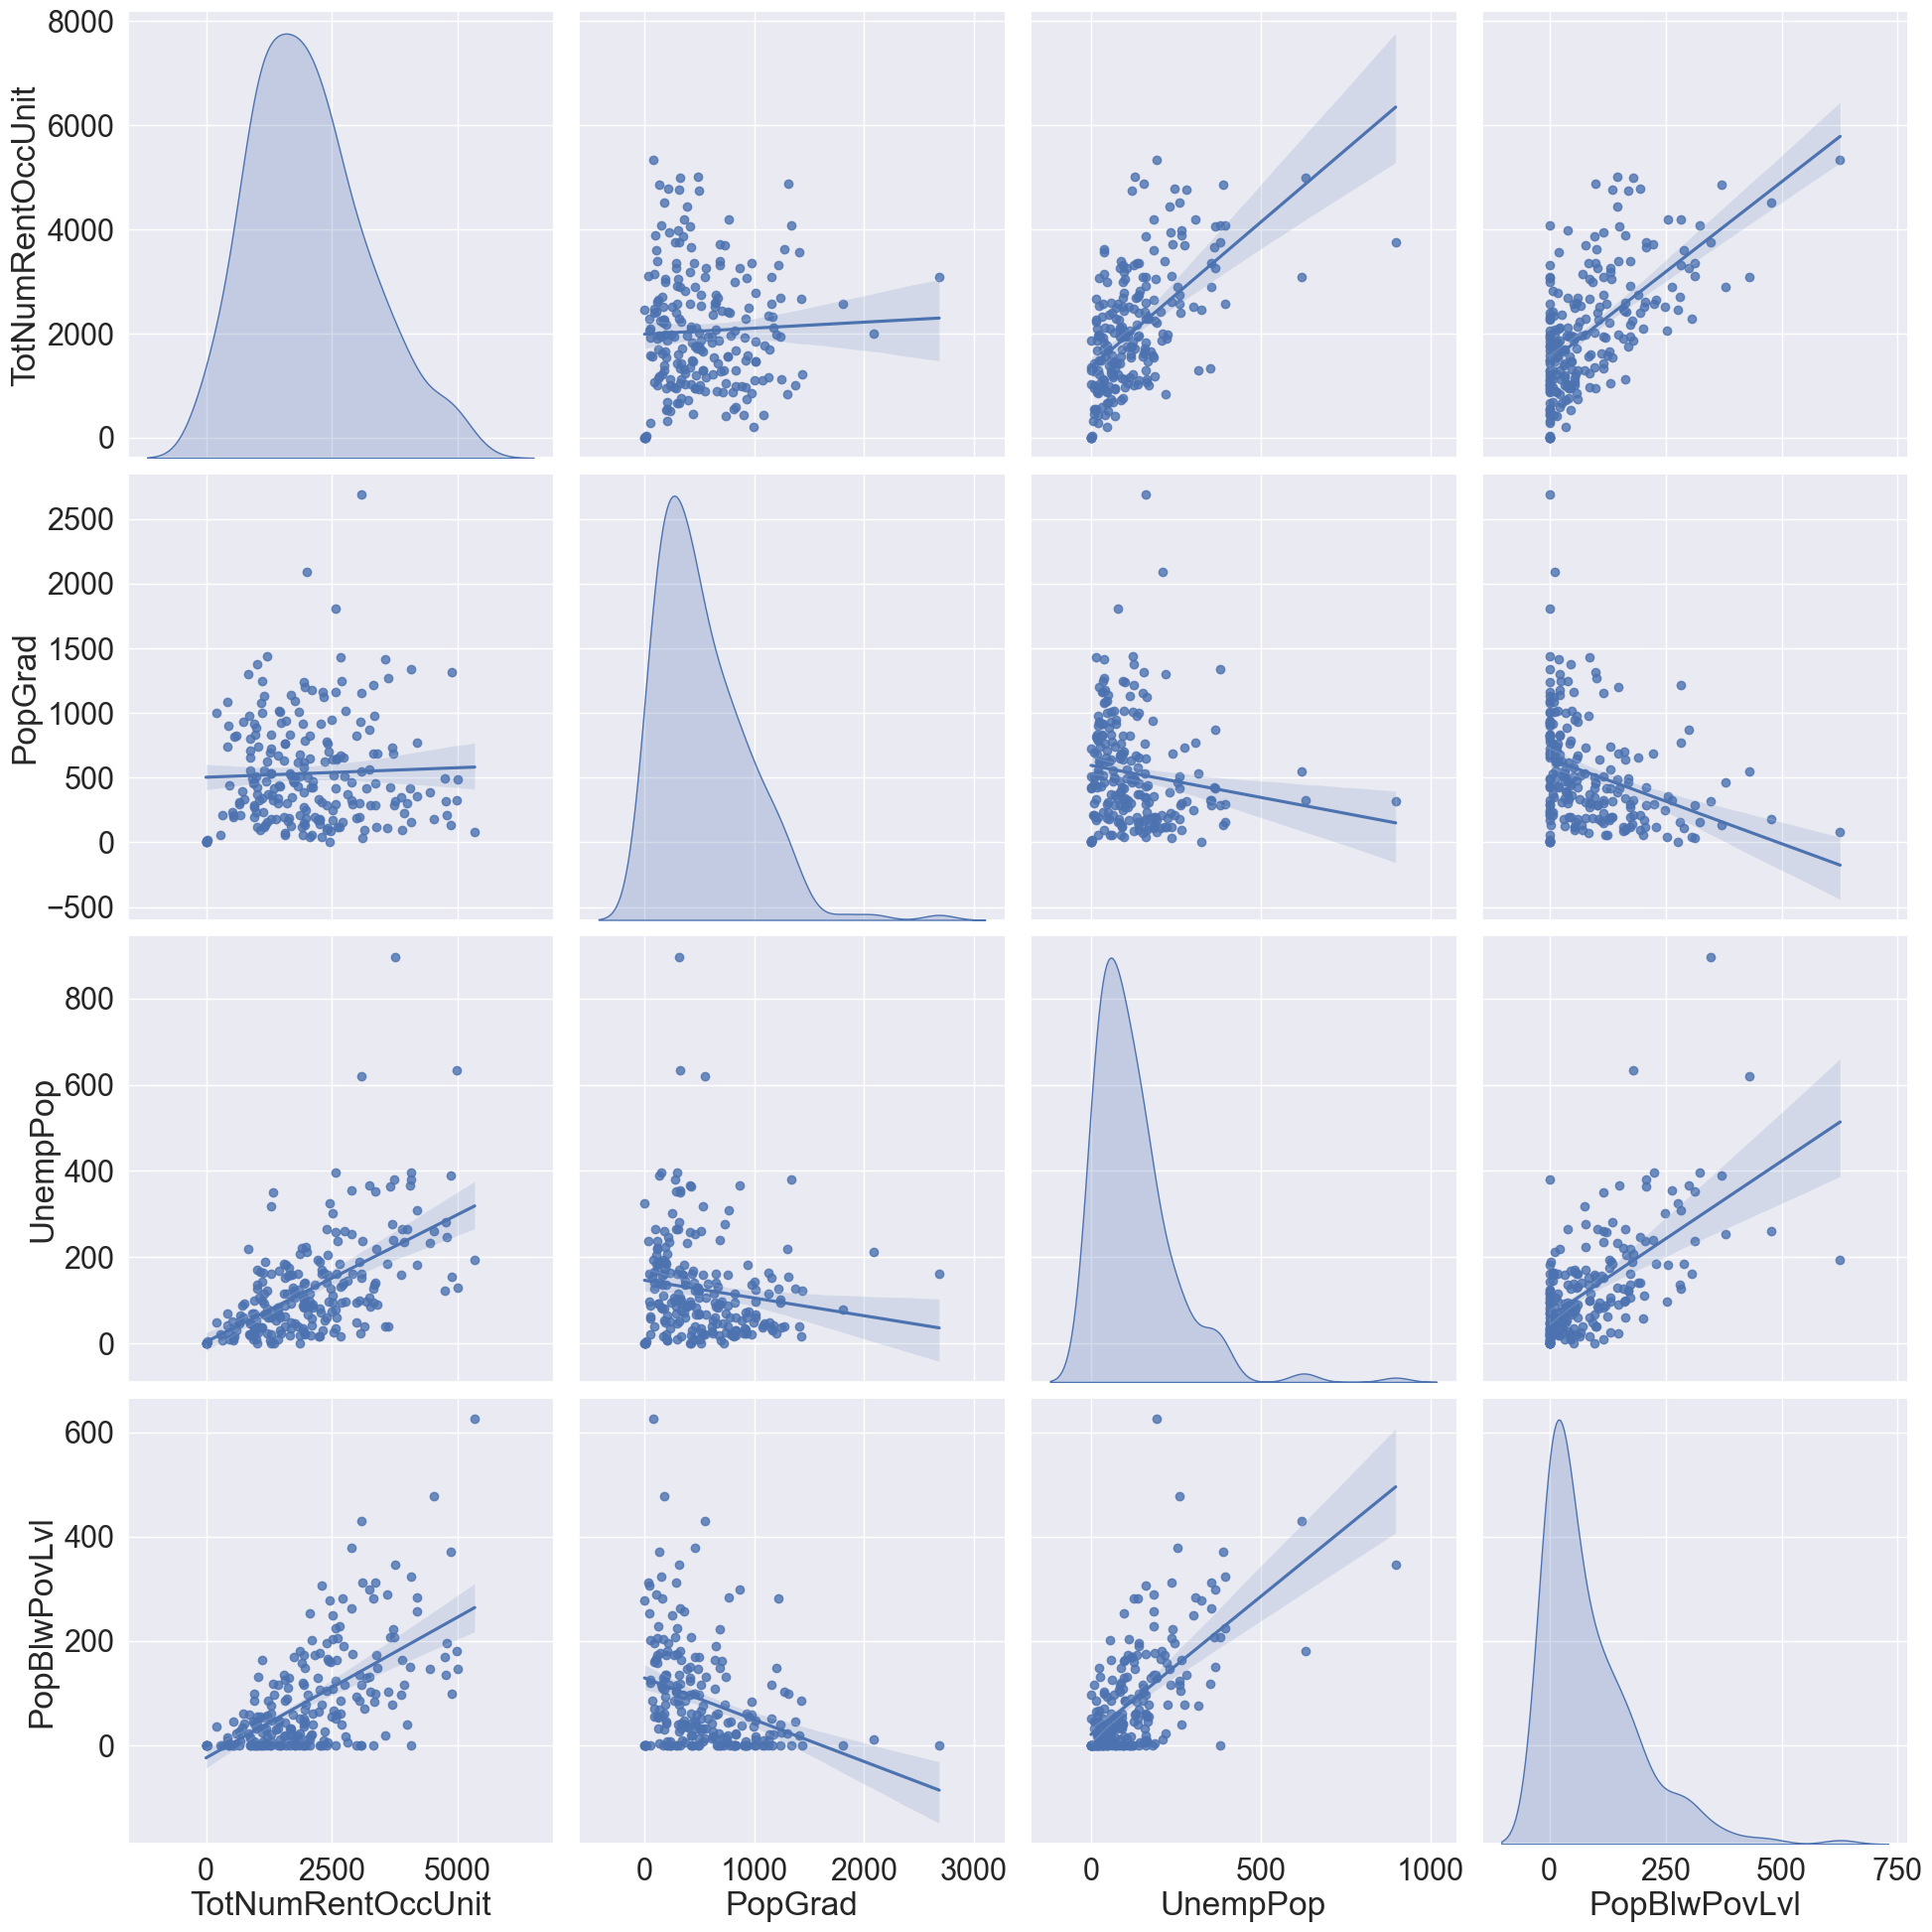

In [22]:
# Importing packages required for additional visualization
import seaborn as sns
sns.set(font_scale=2)

# Given we have 25 variables in the data set to explore, this will be way to many plots to visually inspect. Lets inspect just a handful
sel_vars = [
    "TotNumRentOccUnit", #"Total number of renter occupied units"
    "PopGrad", #"Population with a graduate degree"
    "UnempPop", #"Population in labor force and unemployed"
    "PopBlwPovLvl" #"Population with income below poverty level in past 12 months"
]

pplt = sns.pairplot(
    ma_merge_2[sel_vars], kind="reg", diag_kind="kde",
    height=5, 
)

plt.show()


### Developing Geodemographic Clusters
* **K-means Clustering Algorithm** aims to split your observations into a predefined number of clusters that minimizes within-cluster variance, which measures the similarity of observations that are grouped together in the same cluster. 
* **Agglomerative Hierarchical Geodemographic Clustering (AHC)** starts with each observation in its own cluster and then interactively combines them into a specified number of clusters. 


In [23]:
# Importing the packages needed to scale the data
from sklearn.preprocessing import robust_scale

ma_merged_scaled = robust_scale(ma_merge_2[geo_rn])
ma_merged_scaled


array([[ 1.43330023,  1.47991071,  1.6611274 , ...,  2.79581152,
         0.69398302,  0.53036437],
       [ 1.80359704,  1.93482143,  1.67155425, ...,  1.73472949,
         1.81764489,  2.40890688],
       [ 2.73220788,  2.89866071,  3.4056696 , ...,  3.93368237,
         1.82650425,  2.02024291],
       ...,
       [-1.06388613, -0.94107143, -0.73574454, ..., -0.16404887,
        -1.08674788, -0.40080972],
       [-0.70594726, -0.58660714, -0.22026719, ..., -0.31762653,
        -0.29826504, -0.1417004 ],
       [-0.91823899, -0.79642857, -0.49527533, ..., -0.22687609,
        -0.79734219, -0.06072874]])

In [24]:
# Exploring an initial k-means baseline model
from sklearn.cluster import KMeans
# setting the random seed to ensure reproducibility
np.random.seed(54321)


C:\Users\174006\boston-env\lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\174006\boston-env\lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\174006\boston-env\lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\174006\boston-env\lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the 

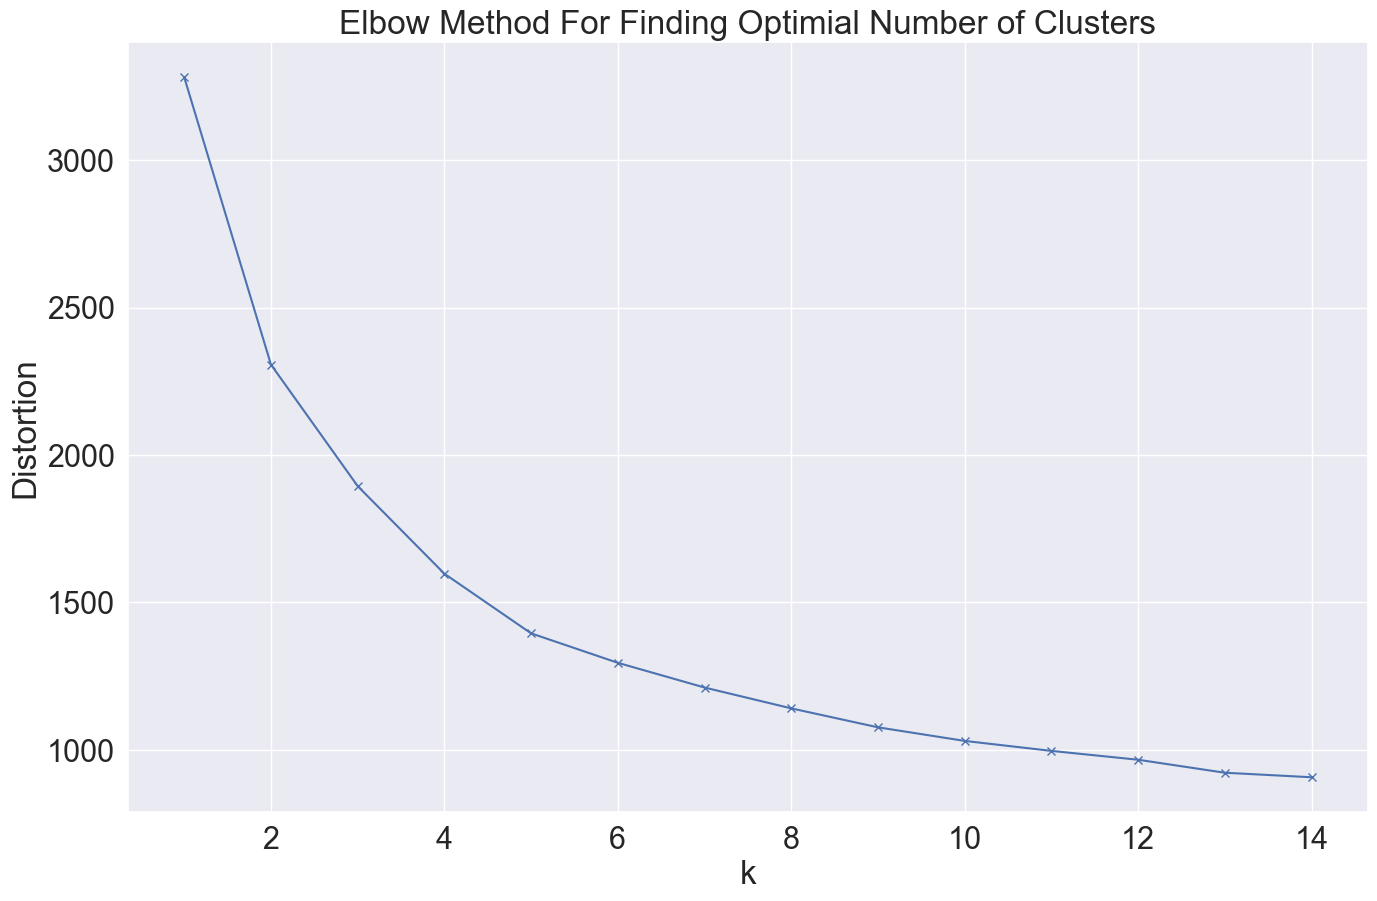

In [25]:
distortions = []
K = range(1,15)
for k in K:
    # Instantiating the model
    kmeans=KMeans(n_clusters=k)
    kmeans.fit(ma_merged_scaled)
    distortions.append(kmeans.inertia_)
    
# Setting the font size
plt.rcParams['font.size'] = '2'

plt.figure(figsize=(16,10))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('Elbow Method For Finding Optimial Number of Clusters')
plt.show()


The optimal number of clusters is determined by finding the bend in the elbow of the plot or the point at which the steepness of the curve begins to decline. Here that point looks to be around five clusters. Not too clear, but lets go with 5.

In [26]:
# Running the KMeans model with 5 clusters
kmeans=KMeans(n_clusters=5)
kmeans_5 = kmeans.fit(ma_merged_scaled)

# Printing the cluster labels
kmeans_5.labels_


C:\Users\174006\boston-env\lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


array([2, 2, 2, 3, 2, 2, 3, 3, 2, 0, 4, 1, 4, 1, 4, 2, 3, 3, 3, 2, 0, 1,
       1, 3, 2, 3, 1, 4, 3, 4, 3, 1, 4, 4, 1, 1, 0, 1, 1, 4, 0, 4, 4, 2,
       3, 4, 1, 4, 1, 4, 1, 4, 0, 0, 0, 2, 4, 1, 1, 1, 3, 2, 2, 3, 2, 2,
       4, 1, 4, 3, 3, 4, 1, 2, 3, 2, 2, 1, 1, 2, 4, 4, 3, 4, 1, 3, 4, 4,
       4, 3, 4, 4, 4, 3, 4, 1, 3, 4, 3, 4, 1, 1, 1, 1, 0, 1, 4, 1, 4, 1,
       4, 3, 1, 1, 3, 3, 3, 1, 0, 1, 2, 1, 3, 2, 1, 3, 1, 1, 1, 3, 1, 3,
       3, 3, 1, 3, 2, 1, 3, 3, 3, 2, 3, 3, 4, 1, 3, 1, 4, 3, 3, 1, 1, 0,
       3, 3, 1, 2, 3, 2, 3, 3, 1, 3, 3, 3, 3, 3, 0, 3, 3, 3, 3, 2, 3, 3,
       3, 2, 3, 3, 2, 3, 4, 4, 3, 3, 2, 3, 3, 3, 2, 3, 3, 2, 2, 3, 3, 2,
       2, 2, 4, 4, 2, 2, 2, 3, 4, 4, 4, 1, 4, 4, 4, 2, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1])

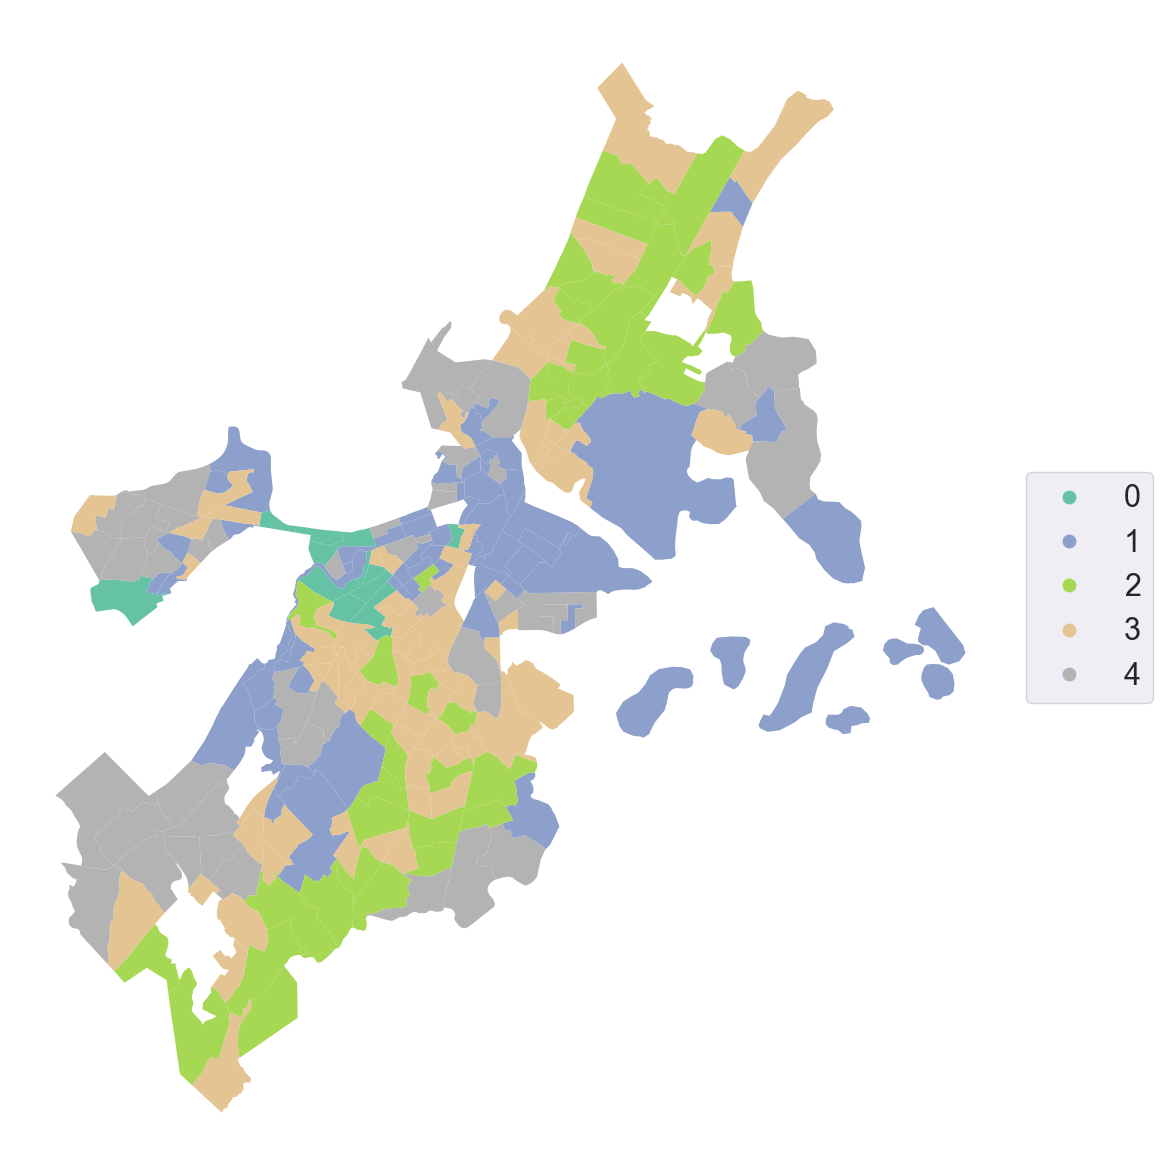

In [28]:
# With the model built, we create a choropleth map to see how the resulting clusters distribute across the city of Boston. 

# Assign labels to a new column called km_5_label
ma_merge_2["kmeans_5_label"] = kmeans_5.labels_

# Setup figure and axis
f, ax = plt.subplots(1, figsize=(20, 20))

# Plot the choropleth map
ma_merge_2.plot(
    column="kmeans_5_label", categorical=True, legend=True, linewidth=0, ax=ax, 
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    cmap="Set2",
)

# Remove the axis
ax.set_axis_off()

# Display the map
plt.show()


The map shows a few concentrations of clusters across space. Cluster 0 has a least concentration, with other clusters well dispersed all around the city. 
* Cluster 4 is visible around West Roxbury, Brighton, sotuh Dorchester, and Charles town.
* Clusters 1, 2 & 3 are well dispersed across the city.

To better understand how the clusters differ from one another, we typically perform a cluster profiling by calculating descriptive statistics to describe the differences and similarities of each cluster.


In [29]:
# calculate the number of census tracts that fall within each of the clusters 

# Group data table by cluster label and count observations
k5distr = ma_merge_2.groupby("kmeans_5_label").size()
k5distr


kmeans_5_label
0    11
1    58
2    39
3    71
4    45
dtype: int64

In [30]:
# Getting the unit of measurement from the CRS
print(ma_merge_2.crs.axis_info)


[Axis(name=Easting, abbrev=X, direction=east, unit_auth_code=EPSG, unit_code=9003, unit_name=US survey foot), Axis(name=Northing, abbrev=Y, direction=north, unit_auth_code=EPSG, unit_code=9003, unit_name=US survey foot)]



The area of the clusters is: kmeans_5_label
0     1.664258
1    16.933954
2    14.301039
3    15.324670
4    15.189460
Name: area, dtype: float64


(array([0, 1, 2, 3, 4]),
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4')])

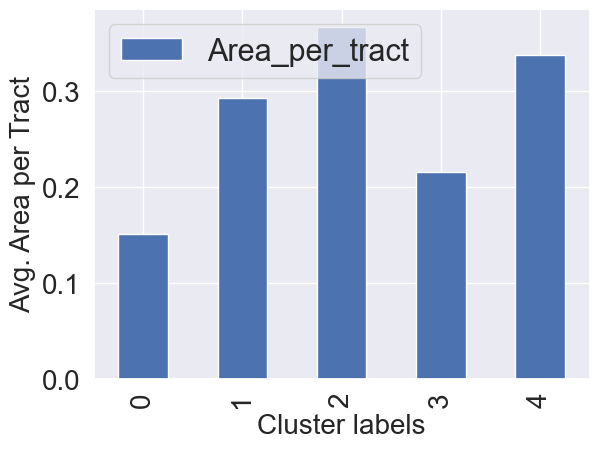

In [31]:
# Calculate the average area of each cluster
# 1. Create a new column with the area of the census tract and convert from foot to sq. mi.
ma_merge_2['area'] = (ma_merge_2.geometry.area)*3.587E-8

# 2. Dissolve the tracts and calculate the area
area = ma_merge_2.dissolve(by="kmeans_5_label", aggfunc="sum")["area"]
print("\nThe area of the clusters is: {}".format(area))

# 3. Create a table with the number of tracts per cluster and the sum area
tract_area = pd.DataFrame({"Num. Tracts": k5distr, "Area": area})
tract_area['Area_per_tract'] = tract_area["Area"]/tract_area["Num. Tracts"]
tract_area.reset_index(inplace=True)

# 4. Plot the area per tract
ax = tract_area.plot.bar(x="kmeans_5_label",y="Area_per_tract")

# Setting size of the labels
plt.xlabel('Cluster labels', fontsize=20)
plt.ylabel('Avg. Area per Tract', fontsize=20)
plt.yticks(fontsize=20)
plt.xticks(fontsize=20)


In [32]:
# Calculating descriptive statistics for each cluster
k5means = ma_merge_2.groupby("kmeans_5_label")[geo_rn].mean()

# Transpose the table and rounding the values to 2 decimal places
k5means.round(2)


,TotPop,TotPopOccUnits,TotNumOwnOccUnit,TotNumRentOccUnit,PopLTHSDip,PopHSDip,PopAssoc,PopBA,PopGrad,PopIncLT10,...,PopInc1525,PopInc2535,PopInc3550,PopInc5065,PopInc6575,PopIncGT75,UnempPop,RetPop,RetPopNoRetInc,PopBlwPovLvl
kmeans_5_label,,,,,,,,,,,,,,,,,,,,,
0,4558.45,1753.64,211.45,1542.18,207.55,135.73,145.82,354.73,380.55,2127.73,...,254.73,194.45,168.27,118.55,62.64,279.82,62.00,56.55,853.00,64.45
1,1786.88,1665.40,693.36,972.03,62.43,133.57,140.90,491.91,568.53,197.24,...,101.97,92.43,140.98,173.95,97.69,610.84,35.34,83.45,784.02,20.41
2,5819.51,5758.56,2231.41,3527.15,838.54,1219.23,930.26,642.31,356.41,780.51,...,683.59,565.77,613.13,388.59,158.62,545.49,284.51,244.33,1757.95,211.74
3,3096.92,3030.23,985.00,2045.23,367.06,548.97,450.87,451.24,297.80,421.15,...,313.58,259.11,298.51,227.56,96.15,392.44,128.42,118.70,1084.11,102.04
4,4456.40,4383.62,2101.40,2282.22,192.04,481.13,515.40,1274.56,1046.93,380.36,...,313.27,301.84,438.11,438.16,298.98,1282.04,108.58,250.40,1731.18,43.36


In [33]:
import plotly.io as pio
pio.renderers.default = 'iframe'

# Creating a dataframe version of the scaled data
ma_merged_scaled_df = pd.DataFrame(ma_merged_scaled,
                  columns = geo_rn)

# Adding in the cluster labels
ma_merged_scaled_df["kmeans_5_label"] = kmeans_5.labels_

# Calculating descriptive statistics for each cluster
k5means_s = ma_merged_scaled_df.groupby("kmeans_5_label")[geo_rn].mean()

# Transpose the table and rounding the values to 2 decimal places
k5means_s.round(2)

import plotly.graph_objects as go

categories = k5means_s.columns
fig = go.Figure()

for g in k5means_s.index:
    fig.add_trace(go.Scatterpolar(
        r = k5means_s.loc[g].values,
        theta = categories,
        fill = 'toself',
        name = f'cluster #{g}'
    ))

fig.update_layout(
  polar=dict(
    radialaxis=dict(
      visible=True,
      range=[-2, 5] # here we can define the range
    )),
  showlegend=True,
    title="KMeans Cluster Radial Plot",
    title_x=0.5
)

fig.show()


Because this is plotted using the scaled version of the data, the scale of the plot is not interpretable, but on a relative basis, we can tell some key differences between the clusters.
* For example, cluster #0 has the highest population with income of less than \\$10,000 while cluster #2 also the highest population with highest unemployment rate.


#### Hierarchical Clustering w/o Spatial Constraint


In [34]:
# Importing the pakage needed for hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

# Set seed for reproducibility
np.random.seed(54321)


In [35]:
# Instantiate the algorithm
model = AgglomerativeClustering(linkage="ward", n_clusters=5)

# Run clustering
model.fit(ma_merged_scaled)

# Assign labels to main dataframe
ma_merge_2["ward5_label"] = model.labels_

# Assign labels to scaled dataframe
ma_merged_scaled_df["ward5_label"] = model.labels_


In [36]:
ward5sizes = ma_merge_2.groupby("ward5_label").size()
ward5sizes


ward5_label
0    119
1     45
2     30
3     10
4     20
dtype: int64

In [37]:
ward5means_s = ma_merged_scaled_df.groupby("ward5_label")[geo_rn].mean()

# Transpose the table and rounding the values to 2 decimal places
ward5means_s.round(2)

categories = ward5means_s.columns
fig = go.Figure()

for g in ward5means_s.index:
    fig.add_trace(go.Scatterpolar(
        r = ward5means_s.loc[g].values,
        theta = categories,
        fill = 'toself',
        name = f'cluster #{g}'
    ))

fig.update_layout(
  polar=dict(
    radialaxis=dict(
      visible=True,
      range=[-2, 6] # here we can define the range
    )),
  showlegend=True,
    title="AHC Cluster Radial Plot",
    title_x=0.5
)

fig.show()


While the interpretation is infeasible, we can still observe that cluster #3 has the population with income of less than \\$10,000 

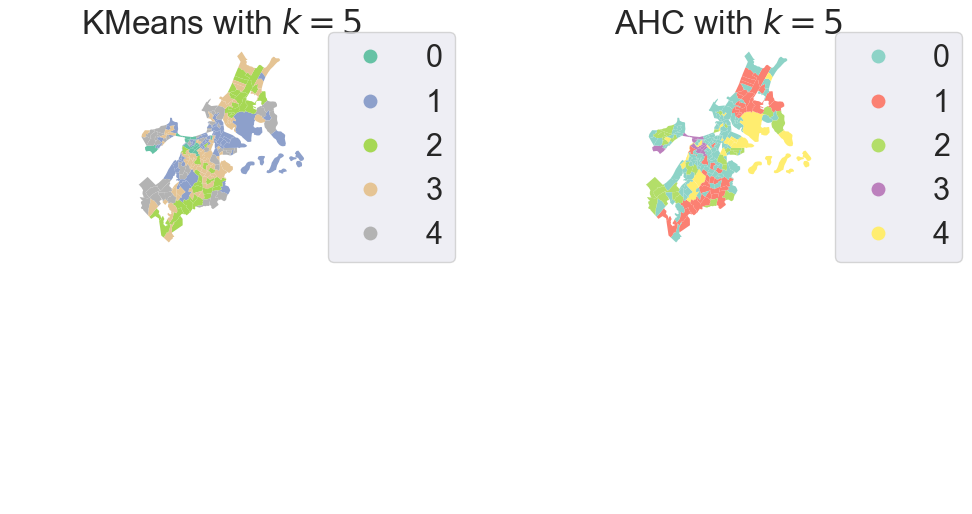

In [38]:
# Setup figure and ax
fig, axs = plt.subplots(2, 2, figsize=(12, 6))

# Plotting the k-means map
ax = axs[0,0]

# Plot the choropleth map of the k-means results
ma_merge_2.plot(
    column="kmeans_5_label",
    categorical=True,
    cmap="Set2",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("KMeans with $k=5$")


# Plot the choropleth map of the Agglomerative Hierarchical Clustering results
ax = axs[0,1]

ma_merge_2.plot(
    column="ward5_label",
    categorical=True,
    cmap="Set3",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("AHC with $k=5$")

# Deleting the empty axis
axs[1,0].set_axis_off()
axs[1,1].set_axis_off()

# Display the map
plt.show()


From the two different clusters, we can see the following:
* Most importantly, cluster #1 in the K-means model is abit similar to cluster #4 (yellow) in the AHC model.
* Cluster #0 in the K-means model similar to cluster #3  in the AHC model.

#### Hierarchical Clustering with Spatial Constraint

We build a AHC model that incorporates a spatial constraint. For some use cases, you may require your clusters to be more spatially connected, or constrained.
* Use cases could include setting service or management boundaries for an organization. This type of clustering is also known as regionalization, as it produces connected geographic clusters or regions.

* To begin constructing the spatially constrained agglomerative hierarchical cluster model, we first need to decide on the spatial constraint, which is a spatial weights matrix. 
Prior to this chapter, we developed a spatial weights matrix to test for spatial autocorrelation. We’ll leverage that weights matrix


In [39]:
# Set the seed for reproducibility
np.random.seed(54321)

# Specify cluster model with a spatial constraint. Constraint is passed using connectivity parameter. 
model = AgglomerativeClustering(
    linkage="ward", connectivity=w.sparse, n_clusters=5
)

# Fit the algorithm to the data
model.fit(ma_merged_scaled)

# Assign the labels to dataframe
ma_merge_2["ward5wgt_label"] = model.labels_

# Assign labels to the scaled dataframe
ma_merged_scaled_df["ward5wgt_label"] = model.labels_


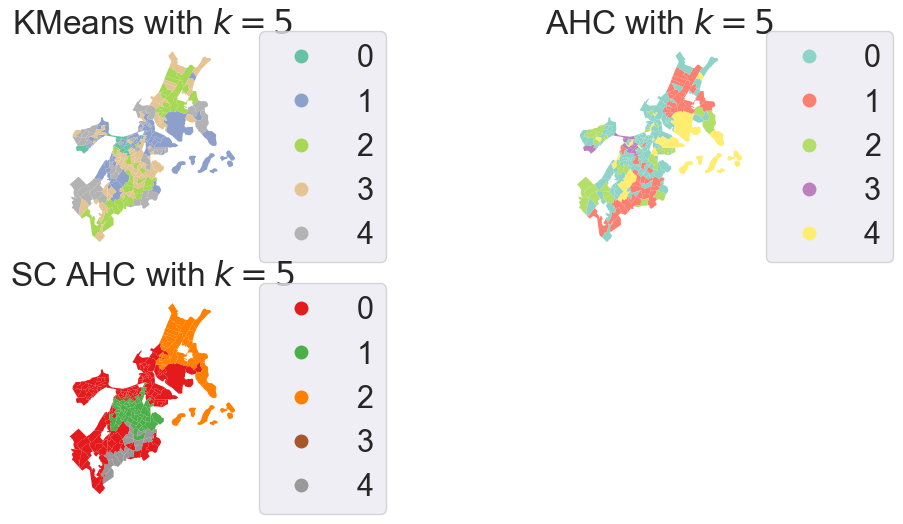

In [40]:
# Setup figure and ax
fig, axs = plt.subplots(2, 2, figsize=(12, 6))

# Plotting the k-means map
ax = axs[0,0]

# Plot the choropleth map of the k-means results
ma_merge_2.plot(
    column="kmeans_5_label",
    categorical=True,
    cmap="Set2",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("KMeans with $k=5$")


# Plot the choropleth map of the Agglomerative Hierarchical Clustering results
ax = axs[0,1]

ma_merge_2.plot(
    column="ward5_label",
    categorical=True,
    cmap="Set3",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("AHC with $k=5$")


# Plot the choropleth map of the Spatially Constrained Agglomerative Hierarchical Clustering results
ax = axs[1, 0]

ma_merge_2.plot(
    column="ward5wgt_label",
    categorical=True,
    cmap="Set1",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("SC AHC with $k=5$")

# Deleting the empty axis
axs[1,1].set_axis_off()

# Display the map
plt.show()


**SCAHC versus AHC versus K-means Clustering Choropleth Maps**

From the maps, the spatially constrained model puts most of the census tracts into the red cluster,followed by orange, then green before grey. Cluster #3 has  the least of the tracts.


In [41]:
# Plot the radial plots for the spatially constrained models
ward5_wgt_means_s = ma_merged_scaled_df.groupby("ward5wgt_label")[geo_rn].mean()

# Transpose the table and rounding the values to 2 decimal places
ward5_wgt_means_s.round(2)

categories = ward5_wgt_means_s.columns
fig = go.Figure()

for g in ward5_wgt_means_s.index:
    fig.add_trace(go.Scatterpolar(
        r = ward5_wgt_means_s.loc[g].values,
        theta = categories,
        fill = 'toself',
        name = f'cluster #{g}'
    ))

fig.update_layout(
  polar=dict(
    radialaxis=dict(
      visible=True,
      range=[-2, 6] # here we can define the range
    )),
  showlegend=True,
    title="SCAHC Cluster Radial Plot",
    title_x=0.5
)

fig.show()


#### K-Nearest Neighbor
Building a final model with a different spatial constraint using 10 k-nearest neighbors (KNN)

In [42]:
# Changing the spatial constraint to use KNN
w = KNN.from_dataframe(ma_merge_2, k=10)


In [43]:
# Setting the seed for reproducibility
np.random.seed(54321)

# Specifying the cluster model with KNN spatial constraint
model = AgglomerativeClustering(linkage="ward", connectivity=w.sparse, n_clusters=5)

# Fitting the algorithm to the data
model.fit(ma_merged_scaled)

# Assigning the labels to dataframe
ma_merge_2["ward5_knnwgt_label"] = model.labels_

# Assigning labels to scaled dataframe
ma_merged_scaled_df["ward5_knnwgt_label"] = model.labels_


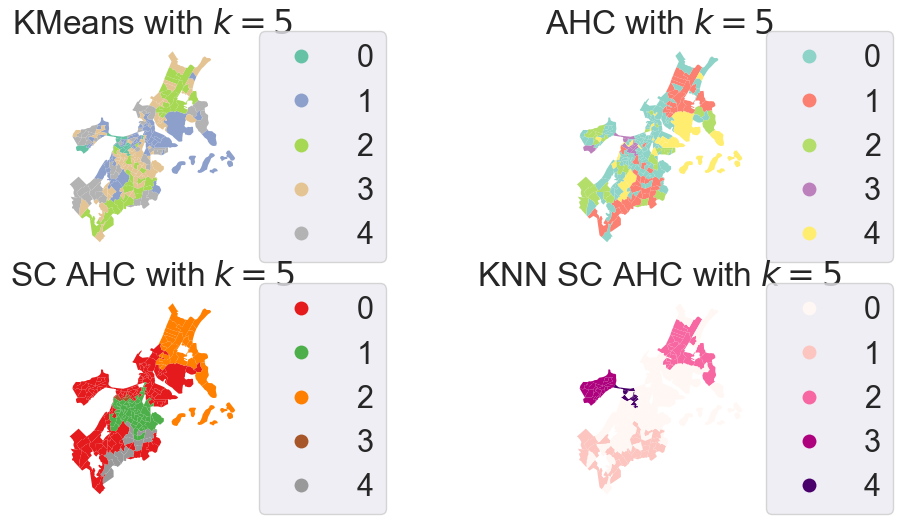

In [44]:
# Setup figure and ax
f, axs = plt.subplots(2, 2, figsize=(12, 6))

# Plotting the k-means map
ax = axs[0,0]
# Plot the choropleth map of the k-means results
ma_merge_2.plot(
    column="kmeans_5_label",
    categorical=True,
    cmap="Set2",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("KMeans with $k=5$")


# Plot the choropleth map of the Agglomerative Hierarchical Clustering results
ax = axs[0,1]

ma_merge_2.plot(
    column="ward5_label",
    categorical=True,
    cmap="Set3",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("AHC with $k=5$")


# Plot the choropleth map of the Spatially Constrained Agglomerative Hierarchical Clustering results
ax = axs[1, 0]

ma_merge_2.plot(
    column="ward5wgt_label",
    categorical=True,
    cmap="Set1",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("SC AHC with $k=5$")

### KNN SC_AHC ###
ax = axs[1,1]

# Plot the choropleth map of the KNN SC AHC results
ma_merge_2.plot(
    column="ward5_knnwgt_label",
    categorical=True,
    cmap="RdPu",
    legend=True,
    legend_kwds={'loc': 'center left','bbox_to_anchor':(1,0.5),'fmt': "{:.0f}"},
    linewidth=0,
    ax=ax,
)
# Remove the axis
ax.set_axis_off()

# Add the title
ax.set_title("KNN SC AHC with $k=5$")

# Display the map
plt.show()


**KNN SCAHC versus SCAHC versus AHC versus K-means Clustering Choropleth Maps**

In [45]:
ward5_knnwgt_s = ma_merged_scaled_df.groupby("ward5_knnwgt_label")[geo_rn].mean()

# Transpose the table and rounding the values to 2 decimal places
ward5_knnwgt_s.round(2)

categories = ward5_knnwgt_s.columns
fig = go.Figure()

for g in ward5_knnwgt_s.index:
    fig.add_trace(go.Scatterpolar(
        r = ward5_knnwgt_s.loc[g].values,
        theta = categories,
        fill = 'toself',
        name = f'cluster #{g}'
    ))

fig.update_layout(
  polar=dict(
    radialaxis=dict(
      visible=True,
      range=[-2, 6] # here we can define the range
    )),
  showlegend=True,
    title="KNN Cluster Radial Plot",
    title_x=0.5
)

fig.show()


### Measuring Model Performance

There are a number of ways to measure the performance of a clustering model and the measurement tells us how well each algorithm is doing in creating segments that have similar observations within each segment while appropriately differentiating segments from one another.

We shall use:
* the Calinski-Harabasz score (Higher scores indicate better models), 
* the Davies-Bouldin score (The minimum score is 0 and lower scores indicate better performance), and 
* the Silhouette measurement scores (Scores are bounded between -1 and 1 where a score of 1 indicates the perfect model performance). 


In [46]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

ch_scores = []
db_scores = []
s_scores = []


In [47]:
for model in ("kmeans_5_label", "ward5_label", "ward5wgt_label", "ward5_knnwgt_label"):
    # compute the CH score
    ch_score = calinski_harabasz_score(
        ma_merged_scaled_df[geo_rn],
        ma_merged_scaled_df[model],
    )
    ch_scores.append((model, ch_score))
    
    # compute the DB score
    db_score = davies_bouldin_score(
        ma_merged_scaled_df[geo_rn],
        ma_merged_scaled_df[model],
    )
    db_scores.append((model, db_score))
    
    # compute the silhouette score
    s_score = silhouette_score(
        ma_merged_scaled_df[geo_rn],
        ma_merged_scaled_df[model],
    )
    s_scores.append((model, s_score))
    

In [48]:
# create a dataframe from the scores
ch_df = pd.DataFrame(
    ch_scores, columns=["model", "CH Score"]
).set_index("model")
db_df = pd.DataFrame(
    db_scores, columns=["model", "DB Score"]
).set_index("model")
s_df = pd.DataFrame(
    s_scores, columns=["model", "Silhouette Score"]
).set_index("model")

# Merging into a combined dataframe
scores_df = ch_df.merge(db_df, on="model")
scores_df = scores_df.merge(s_df, on="model")

# displaying the dataframe
scores_df


,CH Score,DB Score,Silhouette Score
model,,,
kmeans_5_label,74.040029,1.246853,0.218406
ward5_label,65.462692,1.187125,0.195148
ward5wgt_label,26.836975,2.003819,0.065416
ward5_knnwgt_label,31.753433,2.497772,0.057125


* From the model scores above, the non-spatially constrained models perform better mathematically than their spatially constrained counterparts across all measures.
This is to be expected as the spatial constraint limits the ability of the clustering algorithms to minimize within-cluster variance while maximizing between-cluster variance. 
* Depending on your use case, the ability to have geographically contiguous clusters may be more important than the mathematical performance of the model. Although, if mathematical performance is the top priority, you’d want to choose the K-means-based model as it has the best performance statistics.